# 01 · Exploratory Data Analysis — Amazon Electronics Reviews

**Project 2 · Problem 2 · Part 1** (initial analysis of the data)

This notebook answers the six questions of Part 1 and adds a few extra analyses.

| # | Question | Section |
|---|----------|---------|
| 1 | Distribution of `overall` & class imbalance | §2 |
| 2 | Word clouds for positive / neutral / negative reviews | §3 |
| 3 | Top-10 reviewers by total helpful votes | §4 |
| 4 | Review-length histogram & length limits for modelling | §5 |
| 5 | Top-10 products by number of 5-star reviews | §6 |
| 6 | Average rating of the 10 most-reviewed brands | §7 |
| + | Extra insights (length vs. rating, verified purchases, helpfulness) | §8 |

**Conventions:** all shared logic lives in `src/` (data loading, brand cleaning, text cleaning) so that every notebook uses exactly the same preprocessing.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

from src import config, data, text

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

## 1 · Loading the data

Only the columns needed for the analysis are loaded to keep memory low (the full file is ~630 MB on disk).
`asin` and `reviewerID` are read as strings (a few ASINs are 10-digit numbers with leading zeros) and `vote` is parsed from text such as `"1,489"` into integers, where a missing value means *no helpful votes* (= 0).

In [2]:
COLUMNS = ["overall", "vote", "verified", "reviewTime", "reviewerID", "reviewerName", "asin", "reviewText"]
train = data.load_train(columns=COLUMNS)
products = data.load_products()   # one clean row per ASIN: title, brand, brand_key, brand_is_placeholder

print(f"train    : {train.shape[0]:,} reviews x {train.shape[1]} columns")
print(f"products : {len(products):,} unique ASINs (after removing duplicate rows)")
train.head()

train    : 838,944 reviews x 8 columns
products : 756,077 unique ASINs (after removing duplicate rows)


,overall,vote,verified,reviewTime,reviewerID,asin,reviewerName,reviewText
0,2,0,False,2016-11-11,A2OSUEZJIN7BI,0511189877,Chris,I have an older URC-WR7 remote and thought this would be an upgrade (and bec...
1,5,0,True,2016-06-06,A2NETQRG6JHIG7,0511189877,Qrysta White,First time I've EVER had a remote that needed no programming whatsoever so I...
2,4,0,True,2016-03-10,A12JHGROAX49G7,0511189877,Linwood,Got them and only 2 of them worked. company called me after the feedback and...
3,5,0,True,2016-01-14,A1KV65E2TMMG6F,0511189877,Dane Williams,I got tired of the remote being on the wrong side of the bed. I was going to...
4,5,0,True,2016-10-20,A280POPEWI0NSA,0594459451,Kristina H.,"After purchasing cheap cords from another website, I was a little scared to ..."


In [3]:
overview = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "missing_%": (train.isna().mean() * 100).round(2),
})
n_dupes = train.duplicated(["reviewerID", "asin", "reviewTime"]).sum()
print(f"Reviews by the same reviewer for the same ASIN on the same day: {n_dupes:,} ({n_dupes / len(train):.2%})")
overview

Reviews by the same reviewer for the same ASIN on the same day: 8,949 (1.07%)


,dtype,missing,missing_%
overall,int8,0,0.00
vote,int32,0,0.00
verified,bool,0,0.00
reviewTime,str,0,0.00
reviewerID,string,0,0.00
asin,string,0,0.00
reviewerName,str,227,0.03
reviewText,str,0,0.00


**Observations**
- The training set has **838,944 reviews**; every column we loaded is complete except `reviewerName` (227 missing, 0.03 %). `vote` is empty for ~77 % of the raw rows — a missing value simply means *nobody found the review helpful*, so we encode it as 0.
- About **1.1 %** of the rows are the same reviewer reviewing the same ASIN on the same day. These are mostly different variants (colour / size) of one product, so they are *not* removed here; we will revisit this when we split train / validation.
- The shortest review has ~200 characters (see §5): the dataset was evidently pre-filtered to reasonably long reviews, which makes sentiment modelling easier than on raw Amazon data.

## 2 · Q1 — Distribution of `overall` and class imbalance

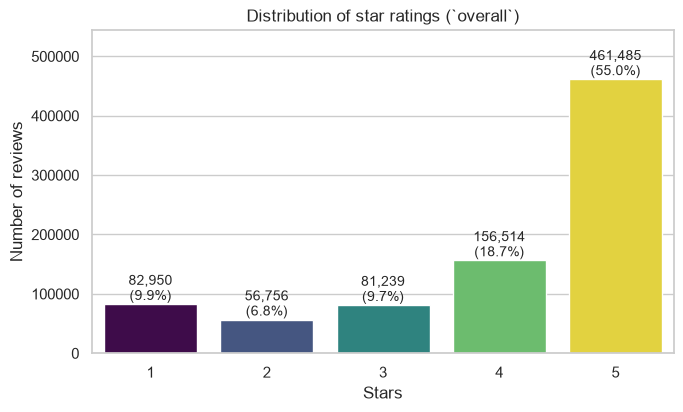

Imbalance ratio (largest / smallest class): 8.1 : 1
Majority-class baseline (always predict 5): accuracy = micro-F1 = 0.550


In [4]:
counts = train["overall"].value_counts().sort_index()
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False, ax=ax)
for i, (n, s) in enumerate(zip(counts.values, share.values)):
    ax.text(i, n, f"{n:,}\n({s:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set(title="Distribution of star ratings (`overall`)", xlabel="Stars", ylabel="Number of reviews", ylim=(0, counts.max() * 1.18))
plt.show()

print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")
print(f"Majority-class baseline (always predict 5): accuracy = micro-F1 = {share.max() / 100:.3f}")

### Is the data balanced? — **No.**
Five-star reviews make up **55 %** of the data while 2-star reviews are only **6.8 %** (imbalance ratio ≈ 8 : 1). A trivial model that always predicts "5" already scores **0.550** — this is the number every model must beat.

### Do we need to balance it for modelling?
Our final metric is **micro-averaged F1**. For single-label multi-class problems micro-F1 *equals accuracy*, i.e. it is computed on the **natural** class distribution. That has two consequences:

1. **Re-sampling the training set to uniform classes (over-/under-sampling) is not our default.** It shifts the model's prior away from the test distribution and typically *lowers* accuracy, even though it raises recall on rare classes.
2. We still must make sure the model actually learns the minority classes (2 and 3 are the hard ones), otherwise it collapses towards "5".

**Proposed strategy (to be verified empirically in notebooks 03/04):**
- **Stratified** train/validation split so every class keeps its share.
- Train with **mild class weights** (e.g. inverse-frequency^0.5) rather than fully balanced ones, and compare against unweighted training on the validation set.
- If compute forces us to subsample, subsample **stratified** (never the first rows: the file is sorted by ASIN).
- Report **macro-F1 and a confusion matrix** next to micro-F1, so we notice if minority classes are ignored.
- Optionally, tune per-class decision offsets on the validation set after training (cheap, and it directly targets micro-F1).

## 3 · Q2 — Word clouds per sentiment class

Rating → class mapping required by the task: **4–5 → positive**, **3 → neutral**, **1–2 → negative**.

*Method.* A random sample of 40,000 reviews per class is cleaned (`text.clean_text`) and counted with `CountVectorizer` (**binary counting**: a term is counted once per review, so one reviewer repeating a word cannot dominate).
Plain frequency clouds are dominated by grammar words and e-commerce filler (*the, product, amazon, bought …*), so unigrams are filtered with an extended stop-word list (`text.CLOUD_STOPWORDS`).
For **bigrams** we use the *light* list (`text.MODEL_STOPWORDS`) that deliberately **keeps negations** — otherwise phrases like *"not work"* or *"not recommend"* would disappear, and those are exactly the phrases that separate negative from positive reviews. Pure negation glue (*does not, did not, but not …*) is removed from the clouds only, because it appears in every class and hides the phrases that follow it; the models in later notebooks still see it.

In [5]:
train["sentiment"] = train["overall"].map(text.sentiment_class)
SENTIMENTS = ["positive", "neutral", "negative"]
print(train["sentiment"].value_counts().reindex(SENTIMENTS).to_frame("n_reviews"))

N_PER_CLASS = 40_000
samples = {
    s: (train.loc[train["sentiment"] == s, "reviewText"]
        .sample(n=min(N_PER_CLASS, int((train["sentiment"] == s).sum())), random_state=config.SEED)
        .map(text.clean_text))
    for s in SENTIMENTS
}

def term_frequencies(docs, ngram_range=(1, 1)):
    """Number of reviews containing each term (uni- or bi-gram), sorted descending."""
    vectorizer = CountVectorizer(
        ngram_range=ngram_range, min_df=5, binary=True, token_pattern=r"(?u)\b[a-z]{2,}\b",
        stop_words=sorted(text.CLOUD_STOPWORDS) if ngram_range == (1, 1) else None,
    )
    matrix = vectorizer.fit_transform(docs)
    freq = pd.Series(np.asarray(matrix.sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out())
    if ngram_range == (2, 2):   # keep bigrams made of informative tokens only (negations survive)
        informative = [term not in text.NEGATION_GLUE_BIGRAMS
                       and not any(tok in text.MODEL_STOPWORDS for tok in term.split()) for term in freq.index]
        freq = freq[informative]
    return freq.sort_values(ascending=False)

unigrams = {s: term_frequencies(samples[s]) for s in SENTIMENTS}
bigrams = {s: term_frequencies(samples[s], (2, 2)) for s in SENTIMENTS}
print({s: f"{len(unigrams[s]):,} unigrams / {len(bigrams[s]):,} bigrams" for s in SENTIMENTS})

           n_reviews
sentiment           
positive      617999
neutral        81239
negative      139706
{'positive': '12,754 unigrams / 25,558 bigrams', 'neutral': '12,963 unigrams / 27,011 bigrams', 'negative': '12,407 unigrams / 24,311 bigrams'}


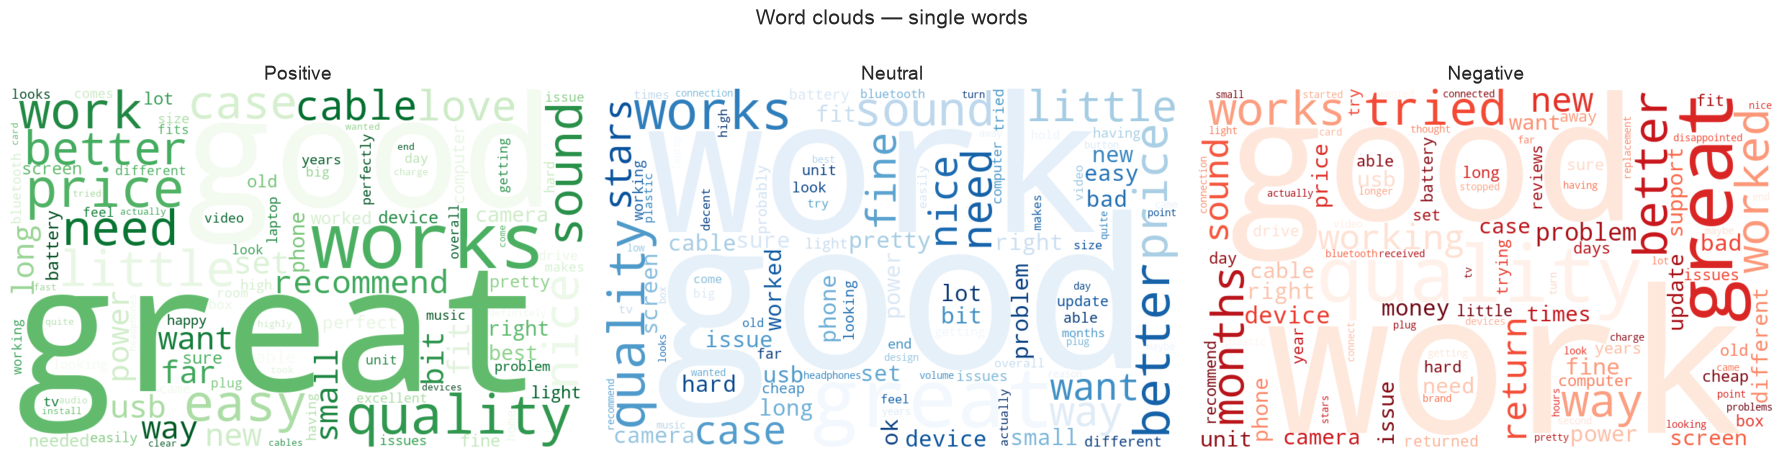

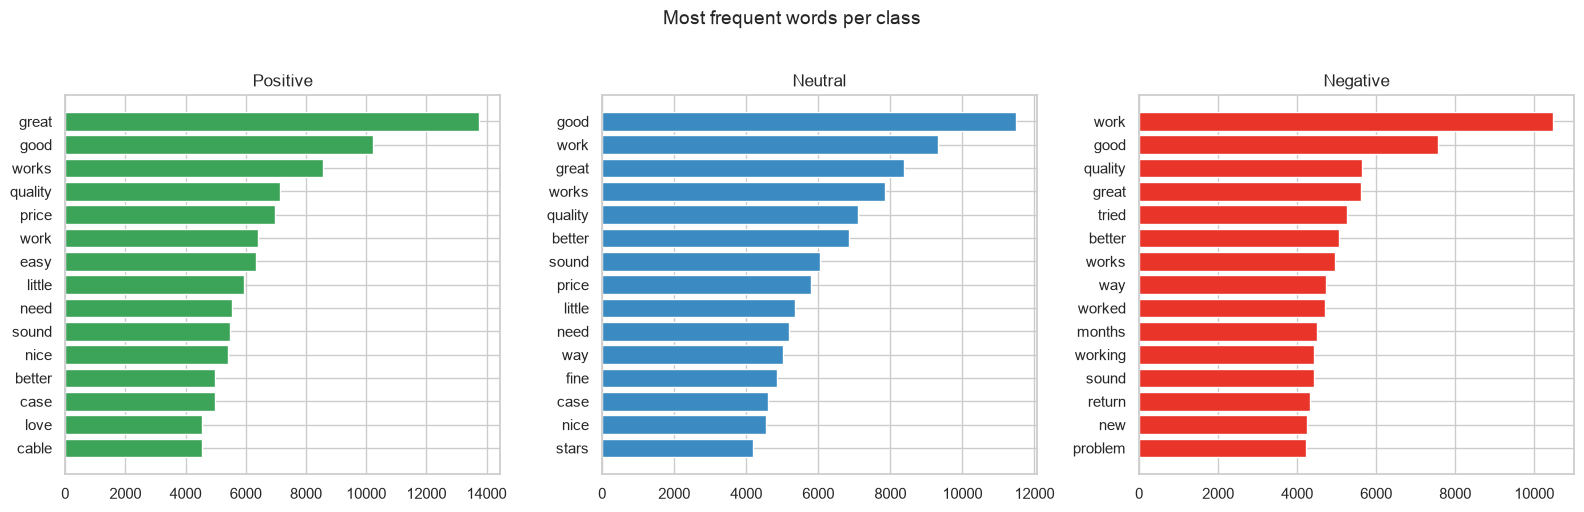

In [6]:
try:
    from wordcloud import WordCloud
except ImportError:          # pip install wordcloud
    WordCloud = None

COLORMAPS = {"positive": "Greens", "neutral": "Blues", "negative": "Reds"}

def plot_term_panels(freqs, title, top_n=15):
    """Horizontal bar charts (always) of the most frequent terms per class."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, s in zip(axes, SENTIMENTS):
        top = freqs[s].head(top_n)[::-1]
        ax.barh(top.index, top.values, color=plt.get_cmap(COLORMAPS[s])(0.65))
        ax.set_title(s.capitalize())
    fig.suptitle(title, y=1.02, fontsize=14)
    plt.tight_layout(); plt.show()

def plot_clouds(freqs, title):
    """Word clouds (needs the optional `wordcloud` package)."""
    if WordCloud is None:
        print("`wordcloud` is not installed -> run `pip install wordcloud` to render the clouds.")
        return
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, s in zip(axes, SENTIMENTS):
        cloud = WordCloud(width=800, height=500, background_color="white", colormap=COLORMAPS[s],
                          max_words=100, random_state=config.SEED).generate_from_frequencies(freqs[s].head(200).to_dict())
        ax.imshow(cloud, interpolation="bilinear"); ax.axis("off"); ax.set_title(s.capitalize(), fontsize=14)
    fig.suptitle(title, fontsize=15); plt.tight_layout(); plt.show()

plot_clouds(unigrams, "Word clouds — single words")
plot_term_panels(unigrams, "Most frequent words per class")

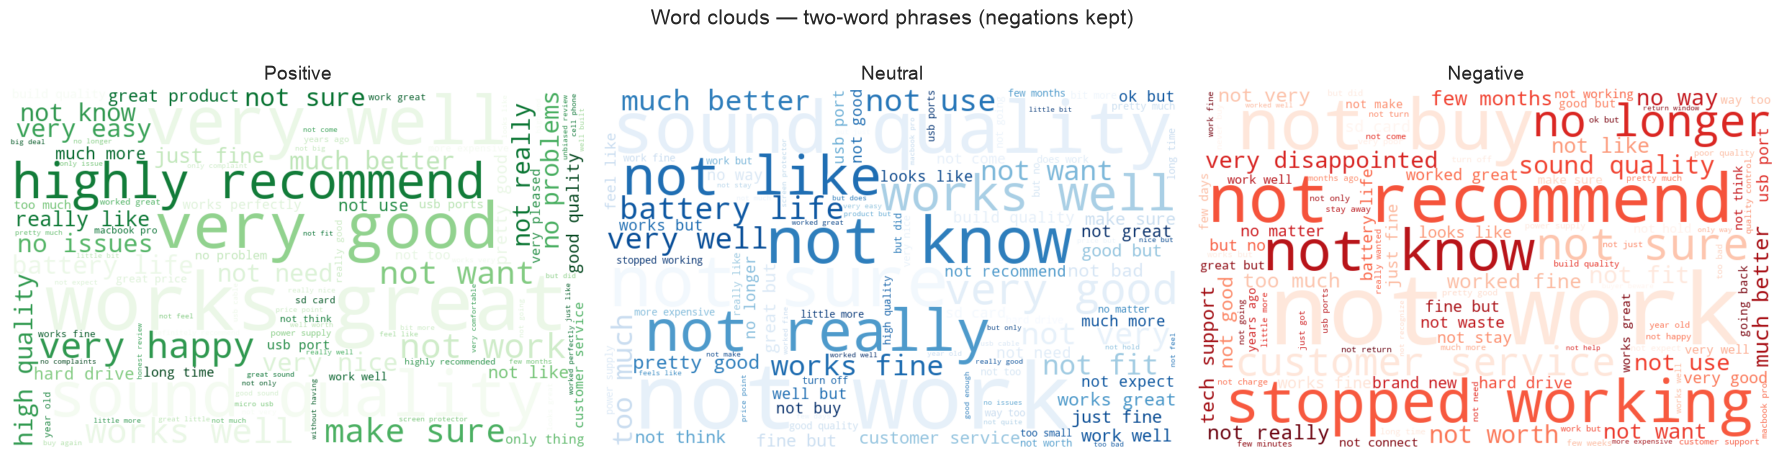

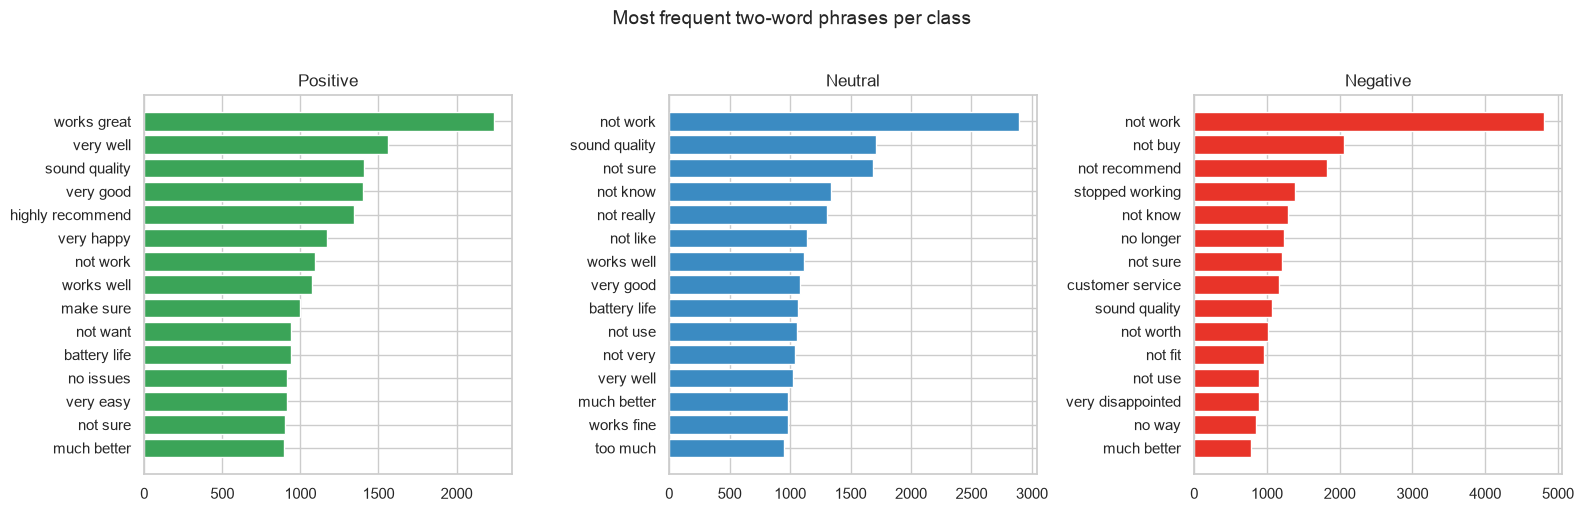

In [7]:
plot_clouds(bigrams, "Word clouds — two-word phrases (negations kept)")
plot_term_panels(bigrams, "Most frequent two-word phrases per class")

### Overlap between classes and what actually distinguishes them
Raw frequency says which words are *common*; to see what is *distinctive* we also compute a smoothed **log-odds ratio** between positive and negative reviews (large positive = typical for positive reviews, large negative = typical for negative reviews). Terms that occur in fewer than 200 sampled reviews are ignored.

Words in BOTH the top-50 of positive and negative reviews: 30  (Jaccard = 0.43)
['battery', 'better', 'cable', 'camera', 'case', 'computer', 'device', 'fine', 'good', 'great', 'hard', 'little', 'need', 'new', 'phone', 'power', 'price', 'quality', 'recommend', 'right', 'screen', 'set', 'sound', 'sure', 'usb', 'want', 'way', 'work', 'worked', 'works']


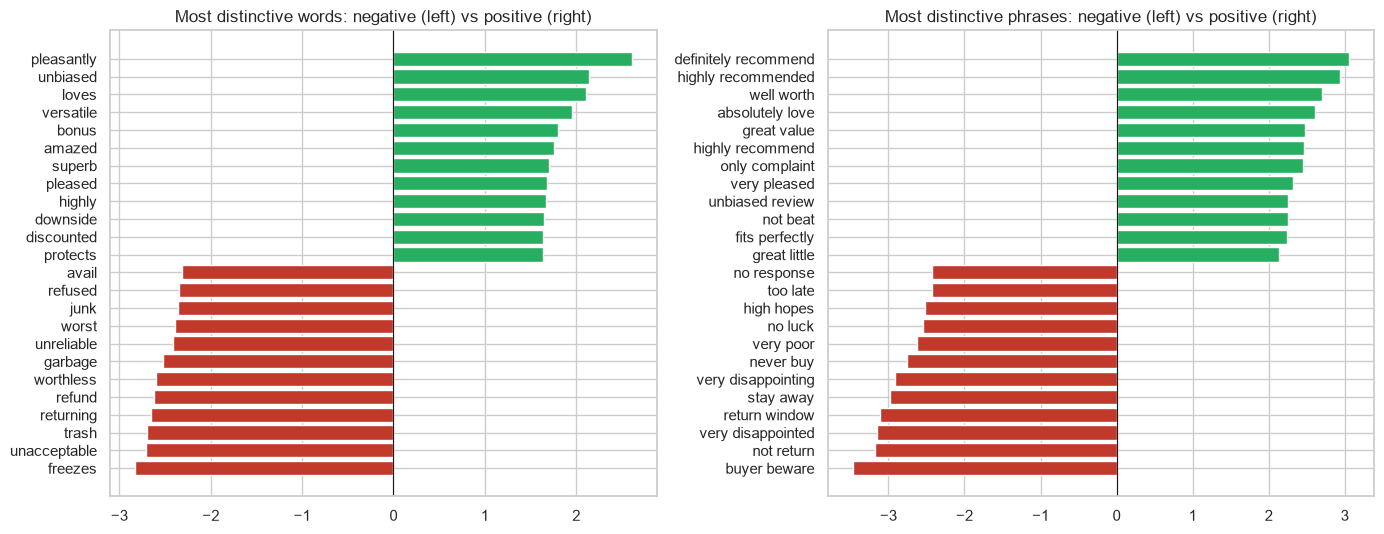

In [8]:
TOP_K = 50
top_sets = {s: set(unigrams[s].head(TOP_K).index) for s in SENTIMENTS}
shared = sorted(top_sets["positive"] & top_sets["negative"])
jaccard = len(top_sets["positive"] & top_sets["negative"]) / len(top_sets["positive"] | top_sets["negative"])
print(f"Words in BOTH the top-{TOP_K} of positive and negative reviews: {len(shared)}  (Jaccard = {jaccard:.2f})")
print(shared)

def log_odds(freq_a, freq_b, alpha=0.5, min_count=200):
    """Smoothed log-odds ratio of every term: log P(t|A) - log P(t|B)."""
    vocab = freq_a.index.union(freq_b.index)
    a, b = freq_a.reindex(vocab, fill_value=0), freq_b.reindex(vocab, fill_value=0)
    keep = (a + b) >= min_count
    a, b = a[keep], b[keep]
    score = np.log((a + alpha) / (a.sum() + alpha * len(a))) - np.log((b + alpha) / (b.sum() + alpha * len(b)))
    return score.sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (freqs, name) in zip(axes, [(unigrams, "words"), (bigrams, "phrases")]):
    lo = log_odds(freqs["positive"], freqs["negative"])
    view = pd.concat([lo.head(12), lo.tail(12)])
    ax.barh(view.index, view.values, color=["#c0392b"] * 12 + ["#27ae60"] * 12)
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"Most distinctive {name}: negative (left) vs positive (right)")
plt.tight_layout(); plt.show()

### Reading the word clouds / bar charts
**Single words.** The three classes share most of their vocabulary: **30 of the top-50 words appear in both the positive and the negative list** (Jaccard ≈ 0.43) — e.g. *good, great, work(s), quality, sound, battery, price, recommend*. Reasons:

- Reviews describe the **same product categories** (cables, cameras, speakers, drives), so topic words are shared.
- **Sentiment words are used on both sides.** Positive words occur in negative reviews inside negated or contrasted statements ("*not* good", "*great* idea but it stopped working after two months"), and negative words such as *work* appear in positive reviews ("works great").
- Neutral (3-star) reviews are a **mix**: *good, great, better, fine* plus *not*/*but* constructions — the model will find 3 stars the hardest class.

**Phrases (bigrams) separate the classes much better than single words** — this is why we kept negations:
- Negative: *not work, not buy, not recommend, stopped working, no longer, customer service, not worth, very disappointed*.
- Positive: *works great, highly recommend, very happy, very easy, no issues, works well*.
- Mixed: *not work* still shows up in positive reviews ("did not work at first, but support fixed it"), which again shows that context matters.

**What is truly distinctive (log-odds chart).** Negative: *freezes, unacceptable, trash, returning, refund, worthless, garbage, buyer beware, return window*; positive: *loves, amazed, superb, pleased, definitely recommend, great value, fits perfectly*. Note also *"unbiased review"* / *"only complaint"* among positive phrases: these typically come from reviewers who received the product for free or at a discount, a source of positive bias.

**Modelling implications**
1. **Do not remove negations** (*not, no, never, n't → not*) as stop-words — they carry the sentiment.
2. Use **n-grams (1–2)** in the linear baseline and a **contextual model** (transformer) for the confusing cases.
3. Words about *returns, refunds, customer service* are strong negative signals that go beyond pure sentiment vocabulary.

*(If the optional `wordcloud` package is installed the cells above also draw the actual clouds; the bar charts are always shown so the analysis does not depend on it.)*

## 4 · Q3 — Top-10 reviewers by total helpful votes

A reviewer's score is the **sum of `vote` over all of their reviews** (grouping by `reviewerID`, because display names such as *Amazon Customer* are shared by many people). The readable name shown is the most frequent name used by that ID.

In [9]:
per_reviewer = train.groupby("reviewerID").agg(total_votes=("vote", "sum"), n_reviews=("vote", "size"))
top_reviewers = per_reviewer.nlargest(10, "total_votes")

names = (train.loc[train["reviewerID"].isin(top_reviewers.index), ["reviewerID", "reviewerName"]]
         .dropna().groupby("reviewerID")["reviewerName"].agg(lambda s: s.mode().iat[0]))
top_reviewers.insert(0, "reviewerName", names.reindex(top_reviewers.index))
top_reviewers.insert(3, "votes_per_review", (top_reviewers["total_votes"] / top_reviewers["n_reviews"]).round(1))
top_reviewers.index = range(1, 11)
top_reviewers

,reviewerName,total_votes,n_reviews,votes_per_review
1,Benson Leung,4572,29,157.7
2,Voltron00x,3181,9,353.4
3,Obi Wan,3150,29,108.6
4,nycebo,2978,2,1489.0
5,Mayra S.,2631,19,138.5
6,Cthulhu,2607,32,81.5
7,Chris Upton,2167,5,433.4
8,Sally B.,1912,5,382.4
9,DJ,1867,24,77.8
10,Mark A. Baker,1820,1,1820.0


**Observations**
- The top reviewer, **Benson Leung**, collected **4,572 helpful votes** across 29 reviews (≈158 per review).
- The ranking is driven by *viral single reviews* as much as by activity: **nycebo** has 2 reviews with 2,978 votes (≈1,489 each) and **Mark A. Baker** reached 1,820 votes with *one* review. Only a few people on the list (Benson Leung, Obi Wan, Cthulhu, DJ) combine many reviews *and* many votes.
- The vote distribution is therefore **extremely heavy-tailed** (max single value in the data: 2,846 votes while ~77 % of reviews have none). If `vote` is used as a model feature it should be log-transformed (`log1p`); we do not use it as the main input.

## 5 · Q4 — Histogram of review length (characters of `reviewText`)

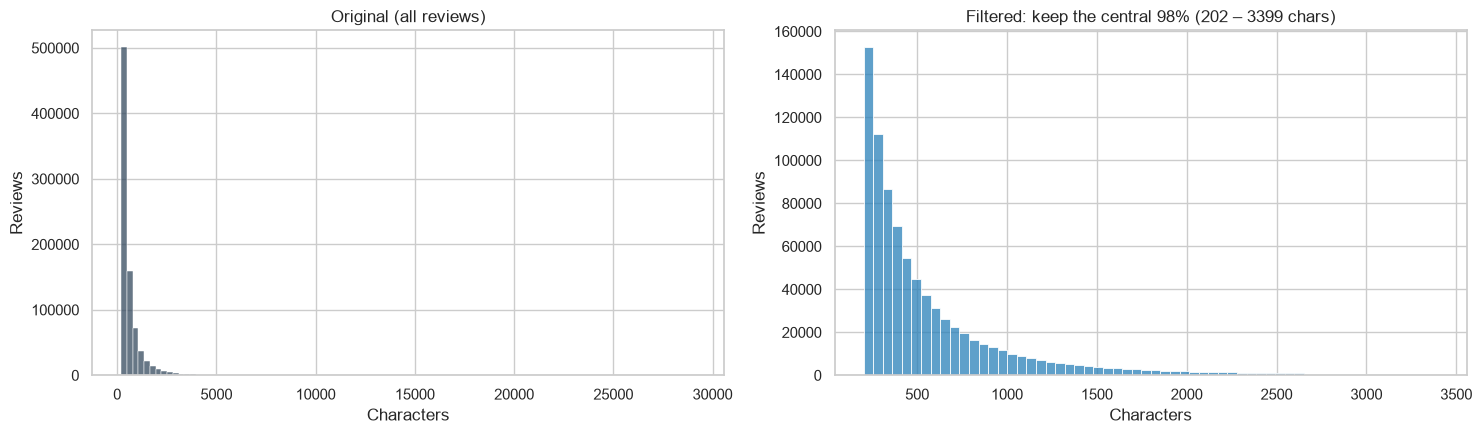

In [10]:
train["n_chars"] = train["reviewText"].str.len().fillna(0).astype("int32")
p1, p99 = train["n_chars"].quantile([0.01, 0.99])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(train["n_chars"], bins=100, ax=axes[0], color="#34495e")
axes[0].set(title="Original (all reviews)", xlabel="Characters", ylabel="Reviews")

trimmed = train.loc[train["n_chars"].between(p1, p99), "n_chars"]
sns.histplot(trimmed, bins=60, ax=axes[1], color="#2980b9")
axes[1].set(title=f"Filtered: keep the central 98% ({p1:.0f} – {p99:.0f} chars)", xlabel="Characters", ylabel="Reviews")
plt.tight_layout(); plt.show()

In [11]:
# str.count avoids materialising one Python list per review (keeps memory low on 8 GB machines)
train["n_words"] = train["reviewText"].str.count(r"\S+").fillna(0).astype("int32")
percentiles = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
length_summary = train[["n_chars", "n_words"]].quantile(percentiles).T.round(0).astype(int)
length_summary.columns = [f"p{p * 100:g}" for p in percentiles]
length_summary["max"] = [train["n_chars"].max(), train["n_words"].max()]
length_summary

,p0.1,p1,p5,p25,p50,p75,p90,p95,p99,p99.9,max
n_chars,200,202,212,277,408,697,1217,1733,3399,7224,29146
n_words,29,35,39,52,76,129,223,316,613,1292,5144


### Reading the histograms
The original histogram is a single spike at the left with an extremely long tail (maximum **29,146 characters**), so nothing else is visible. Restricting to the central 98 % (≈ 202 – 3,399 characters) reveals the real shape: a **right-skewed distribution** with a median of **408 characters (76 words)**; 75 % of reviews are shorter than 697 characters, 95 % shorter than 1,733.

### Do we need a length limit for modelling? — **Yes, an upper one.**

| Model | Lower limit | Upper limit | Reason |
|-------|-------------|-------------|--------|
| TF-IDF + linear | none | optional cap ≈ **3,400 chars (p99)** | bag-of-words is length-robust; the cap only protects memory/time from a handful of giant reviews |
| Transformer | none | **`max_length` = 256 tokens** (≈ 190 words ≈ 1,100 chars), to be compared with 128 | attention cost grows quadratically; 256 tokens already cover roughly 85 % of reviews completely, and our laptop has 8 GB RAM |

- **Lower limit:** not needed — the shortest review is ≈ 200 characters (p0.1 = 200), so there are no empty or trivial texts.
- **Truncation strategy for long reviews:** keep the **head and the tail** (e.g. first 160 + last 96 tokens) instead of only the head, because the verdict ("overall: would not recommend") is often written at the end. We will test this against plain head truncation on the validation set.

## 6 · Q5 — Top-10 products by number of 5-star reviews

In [12]:
five_star = train.loc[train["overall"] == 5, "asin"].value_counts().head(10)
top_products = (five_star.rename("n_five_star_reviews").rename_axis("asin").reset_index()
                .merge(products[["asin", "brand", "title"]], on="asin", how="left"))
top_products["title"] = top_products["title"].str.slice(0, 95)
top_products.index = range(1, 11)
top_products[["brand", "title", "n_five_star_reviews", "asin"]]

,brand,title,n_five_star_reviews,asin
1,Cambridge Soundworks,OontZ Angle 3 Enhanced Stereo Edition IPX5 Splashproof Portable Bluetooth Sp...,1163,B010OYASRG
2,NETGEAR,NETGEAR N300 WiFi Range Extender (EX2700),659,B00L0YLRUW
3,Roku,Roku Streaming Stick (3600R) - HD Streaming Player with Quad-Core Processor,600,B01DA0YCNC
4,StarTech,StarTech USB 2.0 to SATA IDE Adapter (USB2SATAIDE),598,B000VS4HDM
5,Logitech,Logitech M570 Wireless Trackball Mouse – Ergonomic Design with Sculpted Righ...,552,B0043T7FXE
6,Samsung,Samsung 850 EVO 500GB 2.5-Inch SATA III Internal SSD (MZ-75E500B/AM),529,B00OBRE5UE
7,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up to 3167 Mbps) with MU-MIMO to...,471,B00S9SGNNS
8,VideoSecu,"VideoSecu ML531BE TV Wall Mount for Most 27""-55"" LED LCD Plasma Flat Screen ...",448,B000WYVBR0
9,"Arlo Technologies, Inc",Arlo - Wireless Home Security Camera System | Indoor/Outdoor | 2 camera kit ...,433,B00P7EVST6
10,Samsung,Samsung 850 EVO 250GB 2.5-Inch SATA III Internal SSD (MZ-75E250B/AM),431,B00OAJ412U


**Observations**
- The #1 product is a **portable Bluetooth speaker (OontZ Angle 3, sold by Cambridge Soundworks) with 1,163 five-star reviews** — almost twice as many as the runner-up (a NETGEAR WiFi range extender, 659).
- The list is dominated by **well-known accessories and networking / storage gear** (Roku, StarTech, Logitech, Samsung SSDs, Asus router, Arlo cameras) — mainstream products with huge sales, so the count of 5-star reviews mostly reflects *popularity* rather than quality per se. Two Samsung 850 EVO SSD capacities appear separately (#6 and #10), because each capacity is its own ASIN.
- The `brand` column comes from our cleaned product table (case variants merged, HTML entities decoded).

## 7 · Q6 — The 10 most-reviewed brands and their average rating

Brand names are normalised in `data.load_products()` (case variants such as *Sony / SONY* are merged, *"Visit Amazon's … Page"* wrappers are stripped).
The placeholder brand **"Generic"** is not a real brand, so it is excluded from the ranking (its size is reported below for transparency).

In [13]:
reviews_brand = train[["overall", "asin"]].merge(
    products[["asin", "brand", "brand_key", "brand_is_placeholder"]], on="asin", how="left")

print(f"Reviews whose product has no brand: {reviews_brand['brand_key'].isna().sum():,} ({reviews_brand['brand_key'].isna().mean():.2%}) -> ignored")
print(f"Reviews of placeholder brands (Generic, Unknown, ...): {reviews_brand['brand_is_placeholder'].eq(True).sum():,} -> excluded from the ranking")

real_brands = reviews_brand[reviews_brand["brand_is_placeholder"].eq(False)]
brand_stats = real_brands.groupby("brand_key").agg(
    brand=("brand", "first"), n_reviews=("overall", "size"), avg_rating=("overall", "mean"))

top_brands = (brand_stats.nlargest(10, "n_reviews")
              .sort_values("avg_rating", ascending=False)[["brand", "n_reviews", "avg_rating"]])
top_brands["avg_rating"] = top_brands["avg_rating"].round(3)
top_brands.index = range(1, 11)
print(f"Overall mean rating of the whole training set: {train['overall'].mean():.3f}")
top_brands

Reviews whose product has no brand: 1,231 (0.15%) -> ignored
Reviews of placeholder brands (Generic, Unknown, ...): 2,063 -> excluded from the ranking
Overall mean rating of the whole training set: 4.021


,brand,n_reviews,avg_rating
1,Anker,9860,4.244
2,AmazonBasics,13213,4.201
3,Sabrent,7309,4.027
4,SanDisk,8389,3.959
5,Logitech,16993,3.952
6,Samsung,15407,3.941
7,TP-LINK,9773,3.929
8,Sony,11757,3.921
9,Asus,11928,3.856
10,NETGEAR,6659,3.810


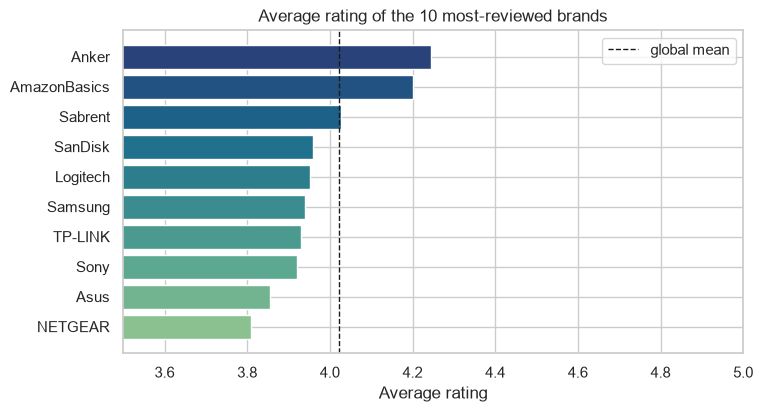

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ordered = top_brands.iloc[::-1]
ax.barh(ordered["brand"], ordered["avg_rating"], color=sns.color_palette("crest", 10))
ax.axvline(train["overall"].mean(), color="k", ls="--", lw=1, label="global mean")
ax.set(xlim=(3.5, 5), xlabel="Average rating", title="Average rating of the 10 most-reviewed brands")
ax.legend(); plt.show()

**Observations**
- Among the ten most-reviewed brands, **Anker (4.24)** and **AmazonBasics (4.20)** are the only ones clearly above the dataset mean (**4.02**); **Sabrent (4.03)** is on par and the other seven are below it.
- **NETGEAR (3.81)** and **Asus (3.86)** have the lowest averages. Both sell mainly routers / networking gear, a category where setup problems and firmware issues are common — a plausible explanation, though we have not verified it here.
- Differences are meaningful: with 6,000 – 17,000 reviews per brand the standard error of each mean is below 0.02 stars.
- The placeholder brand "Generic" is excluded (it has only ~2,000 reviews, so it would not enter the top 10 anyway), and 0.15 % of reviews have no brand and are ignored.

## 8 · Extra insights (useful for feature / modelling decisions)

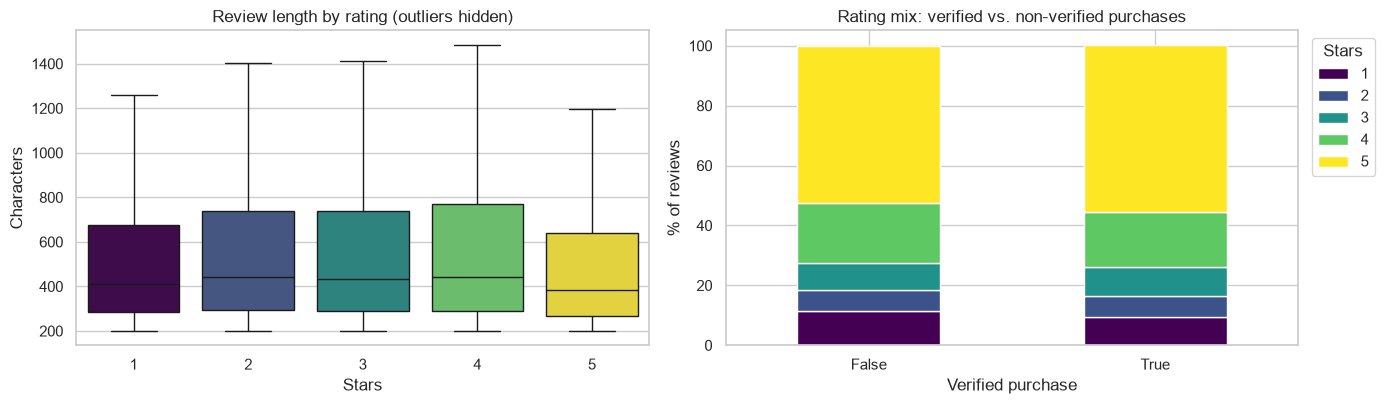

Rating mix (% of reviews) by verified status:
overall      1    2    3     4     5
verified                            
False     11.5  6.8  9.2  20.1  52.3
True       9.6  6.8  9.8  18.4  55.5



,median_chars,mean_chars,median_words
overall,,,
1,416.0,599.0,77.0
2,444.0,652.0,83.0
3,439.0,673.0,83.0
4,447.0,703.0,84.0
5,387.0,591.0,72.0


In [15]:
# (a) Does review length depend on the rating?
by_rating = train.groupby("overall").agg(
    median_chars=("n_chars", "median"), mean_chars=("n_chars", "mean"), median_words=("n_words", "median")).round(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.boxplot(data=train.loc[train["n_chars"] <= p99], x="overall", y="n_chars", hue="overall",
            palette="viridis", legend=False, showfliers=False, ax=axes[0])
axes[0].set(title="Review length by rating (outliers hidden)", xlabel="Stars", ylabel="Characters")

# (b) Verified purchases and (c) helpfulness
verified_share = pd.crosstab(train["verified"], train["overall"], normalize="index").mul(100).round(1)
verified_share.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis", rot=0)
axes[1].set(title="Rating mix: verified vs. non-verified purchases", xlabel="Verified purchase", ylabel="% of reviews")
axes[1].legend(title="Stars", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
print("Rating mix (% of reviews) by verified status:")
print(verified_share)
print()
by_rating

In [16]:
votes_by_rating = train.groupby("overall").agg(
    mean_votes=("vote", "mean"), share_with_votes=("vote", lambda v: (v > 0).mean() * 100)).round(2)
print("Verified-purchase share:", f"{train['verified'].mean():.1%}")
votes_by_rating

Verified-purchase share: 85.9%


,mean_votes,share_with_votes
overall,,
1,2.27,32.86
2,1.35,22.80
3,1.54,22.11
4,1.58,21.23
5,1.75,21.69


### What these extras tell us
1. **Length is a weak signal.** Median lengths are almost identical for 1–4 stars (416–447 characters); 5-star reviews are somewhat *shorter* (median 387). A length feature adds little over the text itself.
2. **Verified purchases:** 85.9 % of reviews are verified. Non-verified reviews are slightly more polarised towards 1 star (11.5 % vs 9.6 %) and slightly less often 5-star (52.3 % vs 55.5 %) — a small effect, but cheap to test as an extra feature in the baseline.
3. **Helpfulness is asymmetric:** 1-star reviews receive the most votes (mean **2.27**, **32.9 %** have at least one vote) versus 21–23 % for 2–5 stars. Readers find *negative* reviews more useful, consistent with the idea that negative reviews contain more concrete, informative content.

## 9 · Summary & decisions for the next notebooks

| Finding | Decision |
|---------|----------|
| 55 % of reviews are 5-star; metric = micro-F1 (= accuracy) | Stratified split, **no hard re-balancing**; test mild class weights; report macro-F1 + confusion matrix |
| Negations & phrases carry the sentiment | Keep negations (`text.MODEL_STOPWORDS`), use 1–2-gram TF-IDF, then a contextual transformer |
| Median 76 words, p95 ≈ 316 words, min ≈ 200 chars | Transformer `max_length` 256 with head + tail truncation; no lower limit |
| `vote` is sparse and heavy-tailed | Optional `log1p(vote)` feature, never the main input |
| `title_brand.csv` has duplicates, HTML entities, brand case variants | Cleaned once in `src/data.py` and reused everywhere |
| File is sorted by ASIN | Always sample **randomly**, never `head()` |

**Next:** `02_aspect_warranty.ipynb` — satisfaction regarding *warranty / guarantee* (Part 2).